<img src="https://github.com/hernancontigiani/ceia_memorias_especializacion/raw/master/Figures/logoFIUBA.jpg" width="500" align="center">


# Procesamiento de lenguaje natural
## Modelo de lenguaje con tokenización por caracteres

### Consigna
- Seleccionar un corpus de texto sobre el cual entrenar el modelo de lenguaje.
- Realizar el pre-procesamiento adecuado para tokenizar el corpus, estructurar el dataset y separar entre datos de entrenamiento y validación.
- Proponer arquitecturas de redes neuronales basadas en unidades recurrentes para implementar un modelo de lenguaje.
- Con el o los modelos que consideren adecuados, generar nuevas secuencias a partir de secuencias de contexto con las estrategias de greedy search y beam search determístico y estocástico. En este último caso observar el efecto de la temperatura en la generación de secuencias.


### Sugerencias
- Durante el entrenamiento, guiarse por el descenso de la perplejidad en los datos de validación para finalizar el entrenamiento. Para ello se provee un callback.
- Explorar utilizar SimpleRNN (celda de Elman), LSTM y GRU.
- rmsprop es el optimizador recomendado para la buena convergencia. No obstante se pueden explorar otros.


In [76]:
import random
import io
import pickle

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

from tensorflow import keras
from tensorflow.keras import layers
from keras.utils import to_categorical
from keras.models import Sequential
from keras.layers import Dense, LSTM, Embedding, Dropout
from tensorflow.keras.losses import SparseCategoricalCrossentropy

### Datos

In [77]:
# descargar de textos.info
import urllib.request

# Para leer y parsear el texto en HTML de wikipedia
import bs4 as bs

In [78]:
raw_html = urllib.request.urlopen('https://www.textos.info/franz-kafka/la-metamorfosis/ebook')
raw_html = raw_html.read()

# Parsear artículo, 'lxml' es el parser a utilizar
article_html = bs.BeautifulSoup(raw_html, 'lxml')

# Encontrar todos los párrafos del HTML (bajo el tag <p>)
# y tenerlos disponible como lista
article_paragraphs = article_html.find_all('p')

article_text = ''

for para in article_paragraphs:
    article_text += para.text + ' '

# pasar todo el texto a minúscula
article_text = article_text.lower()
print(f"Caracteres: {len(article_text):,}")
print(f"Vocabulario: {len(set(article_text))} caracteres distintos")
article_text[:500]

Caracteres: 123,048
Vocabulario: 59 caracteres distintos


' cuando gregorio samsa se despertó una mañana después de un sueño \nintranquilo, se encontró sobre su cama convertido en un monstruoso \ninsecto. estaba tumbado sobre su espalda dura, y en forma de caparazón \ny, al levantar un poco la cabeza veía un vientre abombado, parduzco, \ndividido por partes duras en forma de arco, sobre cuya protuberancia \napenas podía mantenerse el cobertor, a punto ya de resbalar al suelo. \nsus muchas patas, ridículamente pequeñas en comparación con el resto de \nsu tamaño'

In [79]:
from collections import Counter

frec = Counter(article_text)
for ch, n in frec.most_common():
    print(f"{repr(ch):8s} {n:6d}")

' '       20888
'a'       13330
'e'       12660
'o'        8242
'r'        6748
's'        6595
'n'        6250
'i'        4973
'l'        4888
'd'        4767
't'        4218
'u'        3846
'c'        3782
'm'        2832
'p'        2749
'b'        1923
','        1799
'\n'       1616
'g'        1241
'h'        1235
'í'        1122
'q'        1067
'y'         941
'v'         925
'ó'         825
'.'         659
'f'         466
'z'         403
'j'         396
'é'         304
'á'         303
'—'         235
'ñ'         178
';'         122
'x'          93
'ú'          69
'¿'          63
'?'          63
'¡'          51
'!'          51
':'          36
'«'          32
'»'          32
'\t'          4
'ü'           3
'6'           3
'0'           3
'7'           3
'('           2
')'           2
'3'           2
'w'           1
'2'           1
'1'           1
'5'           1
'/'           1
'4'           1
'8'           1
'-'           1


In [80]:
# en article text se encuentra el texto de todo el libro
article_text[:1000]

' cuando gregorio samsa se despertó una mañana después de un sueño \nintranquilo, se encontró sobre su cama convertido en un monstruoso \ninsecto. estaba tumbado sobre su espalda dura, y en forma de caparazón \ny, al levantar un poco la cabeza veía un vientre abombado, parduzco, \ndividido por partes duras en forma de arco, sobre cuya protuberancia \napenas podía mantenerse el cobertor, a punto ya de resbalar al suelo. \nsus muchas patas, ridículamente pequeñas en comparación con el resto de \nsu tamaño, le vibraban desamparadas ante los ojos. «¿qué me ha ocurrido?», pensó. no era un sueño. su habitación, una auténtica habitación humana, si \nbien algo pequeña, permanecía tranquila entre las cuatro paredes harto \nconocidas. por encima de la mesa, sobre la que se encontraba extendido \nun muestrario de paños desempaquetados —samsa era viajante de comercio—,\n estaba colgado aquel cuadro que hacía poco había recortado de una \nrevista y había colocado en un bonito marco dorado. represen

### Elegir el tamaño del contexto

En este caso, como el modelo de lenguaje es por caracteres, todo un gran corpus
de texto puede ser considerado un documento en sí mismo y el tamaño de contexto
puede ser elegido con más libertad en comparación a un modelo de lenguaje tokenizado por palabras y dividido en documentos más acotados.

In [81]:
# seleccionamos el tamaño de contexto
max_context_size = 100

In [82]:
# Usaremos las utilidades de procesamiento de textos y secuencias de Keras
from tensorflow.keras.utils import pad_sequences # se utilizará para padding

In [83]:
# en este caso el vocabulario es el conjunto único de caracteres que existe en todo el texto
chars_vocab = set(article_text)

In [84]:
# la longitud de vocabulario de caracteres es:
len(chars_vocab)

59

In [85]:
# Construimos los dicionarios que asignan índices a caracteres y viceversa.
# El diccionario `char2idx` servirá como tokenizador.
char2idx = {k: v for v,k in enumerate(chars_vocab)}
idx2char = {v: k for k,v in char2idx.items()}

###  Tokenizar

In [86]:
# tokenizamos el texto completo
tokenized_text = [char2idx[ch] for ch in article_text]

In [87]:
tokenized_text[:1000]

[9,
 22,
 55,
 30,
 14,
 51,
 29,
 9,
 50,
 23,
 0,
 50,
 29,
 23,
 43,
 29,
 9,
 6,
 30,
 10,
 6,
 30,
 9,
 6,
 0,
 9,
 51,
 0,
 6,
 31,
 0,
 23,
 1,
 18,
 9,
 55,
 14,
 30,
 9,
 10,
 30,
 37,
 30,
 14,
 30,
 9,
 51,
 0,
 6,
 31,
 55,
 42,
 6,
 9,
 51,
 0,
 9,
 55,
 14,
 9,
 6,
 55,
 0,
 37,
 29,
 9,
 34,
 43,
 14,
 1,
 23,
 30,
 14,
 15,
 55,
 43,
 19,
 29,
 17,
 9,
 6,
 0,
 9,
 0,
 14,
 22,
 29,
 14,
 1,
 23,
 18,
 9,
 6,
 29,
 44,
 23,
 0,
 9,
 6,
 55,
 9,
 22,
 30,
 10,
 30,
 9,
 22,
 29,
 14,
 38,
 0,
 23,
 1,
 43,
 51,
 29,
 9,
 0,
 14,
 9,
 55,
 14,
 9,
 10,
 29,
 14,
 6,
 1,
 23,
 55,
 29,
 6,
 29,
 9,
 34,
 43,
 14,
 6,
 0,
 22,
 1,
 29,
 39,
 9,
 0,
 6,
 1,
 30,
 44,
 30,
 9,
 1,
 55,
 10,
 44,
 30,
 51,
 29,
 9,
 6,
 29,
 44,
 23,
 0,
 9,
 6,
 55,
 9,
 0,
 6,
 31,
 30,
 19,
 51,
 30,
 9,
 51,
 55,
 23,
 30,
 17,
 9,
 47,
 9,
 0,
 14,
 9,
 7,
 29,
 23,
 10,
 30,
 9,
 51,
 0,
 9,
 22,
 30,
 31,
 30,
 23,
 30,
 27,
 18,
 14,
 9,
 34,
 47,
 17,
 9,
 30,
 19,
 9,
 19,
 0,
 38,
 

### Organizando y estructurando el dataset

In [88]:
# separaremos el dataset entre entrenamiento y validación.
# `p_val` será la proporción del corpus que se reservará para validación
# `num_val` es la cantidad de secuencias de tamaño `max_context_size` que se usará en validación
p_val = 0.1
num_val = int(np.ceil(len(tokenized_text)*p_val/max_context_size))

In [89]:
# separamos la porción de texto utilizada en entrenamiento de la de validación.
train_text = tokenized_text[:-num_val*max_context_size]
val_text = tokenized_text[-num_val*max_context_size:]

In [90]:
tokenized_sentences_val = [val_text[init*max_context_size:(init+1)*max_context_size] for init in range(num_val)]

In [91]:
tokenized_sentences_train = [train_text[init:init+max_context_size] for init in range(len(train_text)-max_context_size+1)]

In [92]:
X = np.array(tokenized_sentences_train[:-1])
y = np.array(tokenized_sentences_train[1:])

Nótese que estamos estructurando el problema de aprendizaje como *many-to-many*:

Entrada: secuencia de tokens [$x_0$, $x_1$, ..., $x_N$]

Target: secuencia de tokens [$x_1$, $x_2$, ..., $x_{N+1}$]

De manera que la red tiene que aprender que su salida deben ser los tokens desplazados en una posición y un nuevo token predicho (el N+1).

La ventaja de estructurar el aprendizaje de esta manera es que para cada token de target se propaga una señal de gradiente por el grafo de cómputo recurrente, que es mejor que estructurar el problema como *many-to-one* en donde sólo una señal de gradiente se propaga.

En este punto tenemos en la variable `tokenized_sentences` los versos tokenizados. Vamos a quedarnos con un conjunto de validación que utilizaremos para medir la calidad de la generación de secuencias con la métrica de Perplejidad.

In [93]:
X.shape

(110548, 100)

In [94]:
X[0,:10]

array([ 9, 22, 55, 30, 14, 51, 29,  9, 50, 23])

In [95]:
y[0,:10]

array([22, 55, 30, 14, 51, 29,  9, 50, 23,  0])

In [96]:
vocab_size = len(chars_vocab)

# Definiendo el modelo

In [97]:
from keras.layers import Input, TimeDistributed, CategoryEncoding, SimpleRNN, Dense
from keras.models import Model, Sequential

El modelo que se propone como ejemplo consume los índices de los tokens y los transforma en vectores OHE (en este caso no entrenamos una capa de embedding para caracteres). Esa transformación se logra combinando las capas `CategoryEncoding` que transforma a índices a vectores OHE y `TimeDistributed` que aplica la capa a lo largo de la dimensión "temporal" de la secuencia.

In [98]:
model = Sequential()

model.add(TimeDistributed(CategoryEncoding(num_tokens=vocab_size, output_mode = "one_hot"),input_shape=(None,1)))
model.add(SimpleRNN(200, return_sequences=True, dropout=0.1, recurrent_dropout=0.1 ))
model.add(Dense(vocab_size, activation='softmax'))
model.compile(loss='sparse_categorical_crossentropy', optimizer='rmsprop')

model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ time_distributed_3              │ (None, None, 59)       │             0 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_3 (SimpleRNN)        │ (None, None, 200)      │        52,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, None, 59)       │        11,859 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 63,859 (249.45 KB)

 Trainable params: 63,859 (249.45 KB)

 Non-trainable params: 0 (0.00 B)


### Definir el modelo

Dado que por el momento no hay implementaciones adecuadas de la perplejidad que puedan operar en tiempo de entrenamiento, armaremos un Callback *ad-hoc* que la calcule en cada epoch.

**Nota**: un Callback es una rutina gatillada por algún evento, son muy útiles para relevar datos en diferentes momentos del desarrollo del modelo. En este caso queremos hacer un cálculo cada vez que termina una epoch de entrenamiento.

In [99]:
class PplCallback(keras.callbacks.Callback):

    '''
    Este callback es una solución ad-hoc para calcular al final de cada epoch de
    entrenamiento la métrica de Perplejidad sobre un conjunto de datos de validación.
    La perplejidad es una métrica cuantitativa para evaluar la calidad de la generación de secuencias.
    Además implementa la finalización del entrenamiento (Early Stopping)
    si la perplejidad no mejora después de `patience` epochs.
    '''

    def __init__(self, val_data, history_ppl,patience=5):
      # El callback lo inicializamos con secuencias de validación sobre las cuales
      # mediremos la perplejidad
      self.val_data = val_data

      self.target = []
      self.padded = []

      count = 0
      self.info = []
      self.min_score = np.inf
      self.patience_counter = 0
      self.patience = patience

      # nos movemos en todas las secuencias de los datos de validación
      for seq in self.val_data:

        len_seq = len(seq)
        # armamos todas las subsecuencias
        subseq = [seq[:i] for i in range(1,len_seq)]
        self.target.extend([seq[i] for i in range(1,len_seq)])

        if len(subseq)!=0:

          self.padded.append(pad_sequences(subseq, maxlen=max_context_size, padding='pre'))

          self.info.append((count,count+len_seq))
          count += len_seq

      self.padded = np.vstack(self.padded)


    def on_epoch_end(self, epoch, logs=None):

        # en `scores` iremos guardando la perplejidad de cada secuencia
        scores = []

        predictions = self.model.predict(self.padded,verbose=0)

        # para cada secuencia de validación
        for start,end in self.info:

          # en `probs` iremos guardando las probabilidades de los términos target
          probs = [predictions[idx_seq,-1,idx_vocab] for idx_seq, idx_vocab in zip(range(start,end),self.target[start:end])]

          # calculamos la perplejidad por medio de logaritmos
          scores.append(np.exp(-np.sum(np.log(probs))/(end-start)))

        # promediamos todos los scores e imprimimos el valor promedio
        current_score = np.mean(scores)
        history_ppl.append(current_score)
        print(f'\n mean perplexity: {current_score} \n')

        # chequeamos si tenemos que detener el entrenamiento
        if current_score < self.min_score:
          self.min_score = current_score
          self.model.save("my_model.keras")
          print("Saved new model!")
          self.patience_counter = 0
        else:
          self.patience_counter += 1
          if self.patience_counter == self.patience:
            print("Stopping training...")
            self.model.stop_training = True


### Entrenamiento

In [100]:
# fiteamos, nótese el agregado del callback con su inicialización. El batch_size lo podemos seleccionar a mano
# en general, lo mejor es escoger el batch más grande posible que minimice el tiempo de cada época.
# En la variable `history_ppl` se guardarán los valores de perplejidad para cada época.
history_ppl = []
hist = model.fit(X, y, epochs=20, callbacks=[PplCallback(tokenized_sentences_val,history_ppl)], batch_size=256)

Epoch 1/20
432/432 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step - loss: 2.3283
 mean perplexity: 8.25328270466097 

Saved new model!
432/432 ━━━━━━━━━━━━━━━━━━━━ 37s 80ms/step - loss: 2.3283
Epoch 2/20
432/432 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step - loss: 1.9931
 mean perplexity: 7.16912361883348 

Saved new model!
432/432 ━━━━━━━━━━━━━━━━━━━━ 34s 78ms/step - loss: 1.9931
Epoch 3/20
432/432 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step - loss: 1.8564
 mean perplexity: 6.472627351360936 

Saved new model!
432/432 ━━━━━━━━━━━━━━━━━━━━ 34s 78ms/step - loss: 1.8564
Epoch 4/20
432/432 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step - loss: 1.7654
 mean perplexity: 6.263464239335829 

Saved new model!
432/432 ━━━━━━━━━━━━━━━━━━━━ 34s 78ms/step - loss: 1.7654
Epoch 5/20
432/432 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step - loss: 1.7046
 mean perplexity: 6.053219929818185 

Saved new model!
432/432 ━━━━━━━━━━━━━━━━━━━━ 34s 79ms/step - loss: 1.7046
Epoch 6/20
432/432 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step - loss: 1.6617
 mean perplexity: 5.869954999

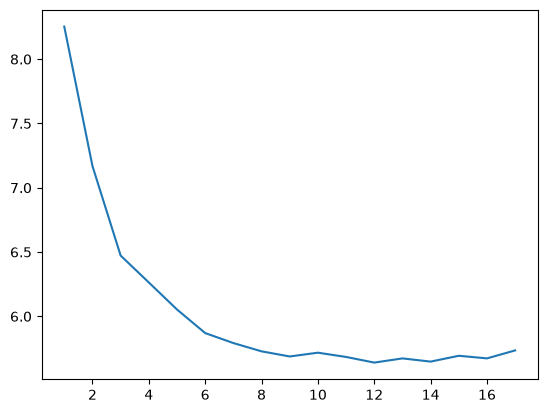

In [101]:
import matplotlib.pyplot as plt
import seaborn as sns

# Entrenamiento
epoch_count = range(1, len(history_ppl) + 1)
sns.lineplot(x=epoch_count,  y=history_ppl)
plt.show()

In [102]:
# Cargamos el mejor modelo guardado del entrenamiento para hacer inferencia
model = keras.models.load_model('my_model.keras')


### Predicción del próximo caracter

In [103]:
# Se puede usar gradio para probar el modelo
# Gradio es una herramienta muy útil para crear interfaces para ensayar modelos
# https://gradio.app/

!pip install -q gradio

zsh:1: command not found: pip


In [105]:
import gradio as gr

def model_response(human_text):

    # Encodeamos
    encoded = [char2idx[ch] for ch in human_text.lower() ]
    # Si tienen distinto largo
    encoded = pad_sequences([encoded], maxlen=max_context_size, padding='pre')

    # Predicción softmax
    y_hat = np.argmax(model.predict(encoded)[0,-1,:])


    # Debemos buscar en el vocabulario el caracter
    # que corresopnde al indice (y_hat) predicho por le modelo
    out_word = ''
    out_word = idx2char[y_hat]

    # Agrego la palabra a la frase predicha
    return human_text + out_word

iface = gr.Interface(
    fn=model_response,
    inputs=["textbox"],
    outputs="text")

iface.launch(debug=True)

/Users/bamazon/Documents/pln_1/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


Keyboard interruption in main thread... closing server.


### Generación de secuencias

In [106]:
def generate_seq(model, seed_text, max_length, n_words):
    """
        Exec model sequence prediction

        Args:
            model (keras): modelo entrenado
            seed_text (string): texto de entrada (input_seq)
            max_length (int): máxima longitud de la sequencia de entrada
            n_words (int): números de caracteres a agregar a la sequencia de entrada
        returns:
            output_text (string): sentencia con las "n_words" agregadas
    """
    output_text = seed_text
	# generate a fixed number of words
    for _ in range(n_words):
		# Encodeamos
        encoded = [char2idx[ch] for ch in output_text.lower() ]
		# Si tienen distinto largo
        encoded = pad_sequences([encoded], maxlen=max_length, padding='pre')

		# Predicción softmax
        y_hat = np.argmax(model.predict(encoded,verbose=0)[0,-1,:])
		# Vamos concatenando las predicciones
        out_word = ''

        out_word = idx2char[y_hat]

		# Agrego las palabras a la frase predicha
        output_text += out_word
    return output_text

In [107]:
input_text='habia una vez'

generate_seq(model, input_text, max_length=max_context_size, n_words=30)

'habia una vez en la cama se asentaba el pad'

###  Beam search y muestreo aleatorio

In [108]:
# funcionalidades para hacer encoding y decoding

def encode(text,max_length=max_context_size):

    encoded = [char2idx[ch] for ch in text]
    encoded = pad_sequences([encoded], maxlen=max_length, padding='pre')

    return encoded

def decode(seq):
    return ''.join([idx2char[ch] for ch in seq])

In [109]:
from scipy.special import softmax

# función que selecciona candidatos para el beam search
def select_candidates(pred,num_beams,vocab_size,history_probs,history_tokens,temp,mode):

  # colectar todas las probabilidades para la siguiente búsqueda
  pred_large = []

  for idx,pp in enumerate(pred):
    pred_large.extend(np.log(pp+1E-10)+history_probs[idx])

  pred_large = np.array(pred_large)

  # criterio de selección
  if mode == 'det':
    idx_select = np.argsort(pred_large)[::-1][:num_beams] # beam search determinista
  elif mode == 'sto':
    idx_select = np.random.choice(np.arange(pred_large.shape[0]), num_beams, p=softmax(pred_large/temp)) # beam search con muestreo aleatorio
  else:
    raise ValueError(f'Wrong selection mode. {mode} was given. det and sto are supported.')

  # traducir a índices de token en el vocabulario
  new_history_tokens = np.concatenate((np.array(history_tokens)[idx_select//vocab_size],
                        np.array([idx_select%vocab_size]).T),
                      axis=1)

  # devolver el producto de las probabilidades (log) y la secuencia de tokens seleccionados
  return pred_large[idx_select.astype(int)], new_history_tokens.astype(int)


def beam_search(model,num_beams,num_words,input,temp=1,mode='det'):

    # first iteration

    # encode
    encoded = encode(input)

    # first prediction
    y_hat = model.predict(encoded,verbose=0)[0,-1,:]

    # get vocabulary size
    vocab_size = y_hat.shape[0]

    # initialize history
    history_probs = [0]*num_beams
    history_tokens = [encoded[0]]*num_beams

    # select num_beams candidates
    history_probs, history_tokens = select_candidates([y_hat],
                                        num_beams,
                                        vocab_size,
                                        history_probs,
                                        history_tokens,
                                        temp,
                                        mode)

    # beam search loop
    for i in range(num_words-1):

      preds = []

      for hist in history_tokens:

        # actualizar secuencia de tokens
        input_update = np.array([hist[i+1:]]).copy()

        # predicción
        y_hat = model.predict(input_update,verbose=0)[0,-1,:]

        preds.append(y_hat)

      history_probs, history_tokens = select_candidates(preds,
                                                        num_beams,
                                                        vocab_size,
                                                        history_probs,
                                                        history_tokens,
                                                        temp,
                                                        mode)

    return history_tokens[:,-(len(input)+num_words):]

In [110]:
# predicción con beam search
salidas = beam_search(model,num_beams=10,num_words=20,input="habia una vez")

In [111]:
salidas[0]

array([48, 30, 44, 43, 30,  9, 55, 14, 30,  9, 38,  0, 27,  9, 51,  0,  9,
       19, 30,  9, 48, 30, 44, 43,  1, 30, 22, 43, 18, 14,  9, 51,  0])

In [112]:
# veamos las salidas
decode(salidas[0])

'habia una vez de la habitación de'

---
# Solución del desafío

Desde acá se desarrolla la resolución de la consigna: corpus propio, armado del
dataset, comparación de arquitecturas recurrentes y generación de secuencias con
las distintas estrategias de búsqueda.
---

## 1. Armado del dataset

Se rehace el preprocesamiento con parámetros propios antes de comparar arquitecturas.
El esquema de aprendizaje es el mismo del ejemplo (many-to-many: la entrada es una
ventana de caracteres y el target es esa misma ventana corrida una posición), pero con
tres diferencias:

- **Vocabulario ordenado.** El orden de iteración de un `set` de strings varía entre
  ejecuciones de Python, de modo que los índices asignados a cada carácter cambiarían en
  cada corrida y un modelo guardado dejaría de ser compatible con su tokenizador.
  Ordenar el vocabulario hace reproducible la tokenización.
- **Validación con secuencias contiguas de largo fijo.** El conjunto de validación se
  recorta a un múltiplo exacto del tamaño de contexto, de forma que todas las secuencias
  midan lo mismo. Esto importa porque la perplejidad sobre validación es el criterio de
  early stopping y el que se usará para comparar las arquitecturas.
- **Ventana deslizante con paso `stride=2` y target explícito.** Avanzar la ventana de a
  un carácter genera una secuencia por posición del texto, casi todas idénticas a la
  anterior. Con paso 2 se reduce el dataset a la mitad conservando un solapamiento del
  98%, lo que permite entrenar LSTM y GRU —más costosas que SimpleRNN— en tiempos
  comparables. Al no ser el paso igual a 1, el target ya no puede obtenerse desplazando
  la lista de secuencias y se construye explícitamente.

In [113]:

# Solución: armado del dataset
# =========================
import numpy as np

max_context_size = 100
stride = 2
p_val = 0.1

# Vocabulario ordenado: set() no garantiza el mismo orden entre corridas,
# así que ordenarlo hace reproducible la asignación de índices
chars_vocab = sorted(set(article_text))
char2idx = {ch: i for i, ch in enumerate(chars_vocab)}
idx2char = {i: ch for ch, i in char2idx.items()}
vocab_size = len(chars_vocab)

tokenized_text = [char2idx[ch] for ch in article_text]

# Separación train/val: recortamos a un múltiplo exacto del contexto
# para que todas las secuencias de validación tengan el mismo largo
n_val = int(len(tokenized_text) * p_val)
n_val -= n_val % max_context_size

train_text = tokenized_text[:-n_val]
val_text = tokenized_text[-n_val:]

# Validación: secuencias contiguas, sin solapamiento
tokenized_sentences_val = [val_text[i:i+max_context_size]
                           for i in range(0, len(val_text), max_context_size)]

# Entrenamiento: ventana deslizante con paso `stride`.
# El target es la misma ventana corrida un carácter (esquema many-to-many).
starts = range(0, len(train_text) - max_context_size - 1, stride)
X = np.array([train_text[i:i+max_context_size] for i in starts])
y = np.array([train_text[i+1:i+1+max_context_size] for i in starts])

print(f"Vocabulario: {vocab_size}")
print(f"Secuencias de entrenamiento: {X.shape}")
print(f"Secuencias de validación: {len(tokenized_sentences_val)} de largo "
      f"{len(tokenized_sentences_val[0])}")

Vocabulario: 59
Secuencias de entrenamiento: (55324, 100)
Secuencias de validación: 123 de largo 100


## 2. Arquitecturas propuestas

Se comparan tres celdas recurrentes sobre el mismo dataset: SimpleRNN (celda de Elman),
LSTM y GRU. Las tres comparten la estructura del ejemplo —codificación one-hot por paso
temporal, capa recurrente con `return_sequences=True` y capa densa con softmax— y
difieren únicamente en el tipo de unidad recurrente, de modo que la diferencia de
perplejidad sea atribuible a la celda y no a otros factores.

El SimpleRNN se reentrena con este dataset en lugar de reutilizar el resultado de la
sección anterior, porque aquel se entrenó con otro paso de ventana y otra partición de
validación: sus perplejidades no serían comparables.

LSTM y GRU se definen sin `recurrent_dropout`. Además de ser más costosas por tener
más compuertas (4 y 3 respectivamente frente a 1 del SimpleRNN), el dropout recurrente
impide usar la implementación optimizada de Keras y multiplica el tiempo por época. Se
conserva el dropout sobre las entradas.

In [114]:
import shutil
from keras.models import Sequential
from keras.layers import TimeDistributed, CategoryEncoding, SimpleRNN, LSTM, GRU, Dense

UNIDADES = 200

def construir(tipo):
    """Misma arquitectura, cambiando sólo la celda recurrente"""
    capa = {"SimpleRNN": SimpleRNN, "LSTM": LSTM, "GRU": GRU}[tipo]

    modelo = Sequential(name=tipo)
    modelo.add(TimeDistributed(
        CategoryEncoding(num_tokens=vocab_size, output_mode="one_hot"),
        input_shape=(None, 1)))

    if tipo == "SimpleRNN":
        modelo.add(capa(UNIDADES, return_sequences=True, dropout=0.1, recurrent_dropout=0.1))
    else:
        modelo.add(capa(UNIDADES, return_sequences=True, dropout=0.1))

    modelo.add(Dense(vocab_size, activation='softmax'))
    modelo.compile(loss='sparse_categorical_crossentropy', optimizer='rmsprop')
    return modelo

In [115]:
resultados = {}

for tipo in ["SimpleRNN", "LSTM", "GRU"]:
    print(f"\n{'='*50}\nEntrenando {tipo}\n{'='*50}")

    # El callback escribe en la variable global `history_ppl`, así que hay que
    # reiniciarla antes de cada entrenamiento
    history_ppl = []

    modelo = construir(tipo)
    modelo.fit(X, y,
               epochs=20,
               batch_size=256,
               callbacks=[PplCallback(tokenized_sentences_val, history_ppl, patience=3)])

    # El callback guarda siempre en "my_model.keras": lo renombramos para no pisarlo
    shutil.copy("my_model.keras", f"modelo_{tipo}.keras")
    resultados[tipo] = list(history_ppl)

    print(f"{tipo}: mejor perplejidad {min(history_ppl):.3f} en época {np.argmin(history_ppl)+1}")


Entrenando SimpleRNN
Epoch 1/20


/Users/bamazon/Documents/pln_1/.venv/lib/python3.11/site-packages/keras/src/layers/core/wrapper.py:25: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


216/217 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step - loss: 2.5314
 mean perplexity: 9.158071060490801 

Saved new model!
217/217 ━━━━━━━━━━━━━━━━━━━━ 21s 89ms/step - loss: 2.5313
Epoch 2/20
216/217 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step - loss: 2.1251
 mean perplexity: 8.222722739708132 

Saved new model!
217/217 ━━━━━━━━━━━━━━━━━━━━ 18s 83ms/step - loss: 2.1251
Epoch 3/20
216/217 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step - loss: 2.0343
 mean perplexity: 7.612434119713016 

Saved new model!
217/217 ━━━━━━━━━━━━━━━━━━━━ 18s 83ms/step - loss: 2.0344
Epoch 4/20
216/217 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step - loss: 1.9542
 mean perplexity: 7.217197922187123 

Saved new model!
217/217 ━━━━━━━━━━━━━━━━━━━━ 18s 83ms/step - loss: 1.9542
Epoch 5/20
216/217 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step - loss: 1.8859
 mean perplexity: 6.833082400686372 

Saved new model!
217/217 ━━━━━━━━━━━━━━━━━━━━ 18s 83ms/step - loss: 1.8859
Epoch 6/20
216/217 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step - loss: 1.8294
 mean perplexity: 6.574664133351024 



In [118]:
import pandas as pd
import matplotlib.pyplot as plt

tabla = pd.DataFrame([
    {"Arquitectura": k,
     "Mejor perplejidad": round(min(v), 3),
     "Época del mínimo": int(np.argmin(v)) + 1,
     "Épocas corridas": len(v)}
    for k, v in resultados.items()
]).sort_values("Mejor perplejidad").reset_index(drop=True)

tabla

,Arquitectura,Mejor perplejidad,Época del mínimo,Épocas corridas
0,SimpleRNN,5.699,20,20
1,GRU,5.747,12,15
2,LSTM,6.524,20,20


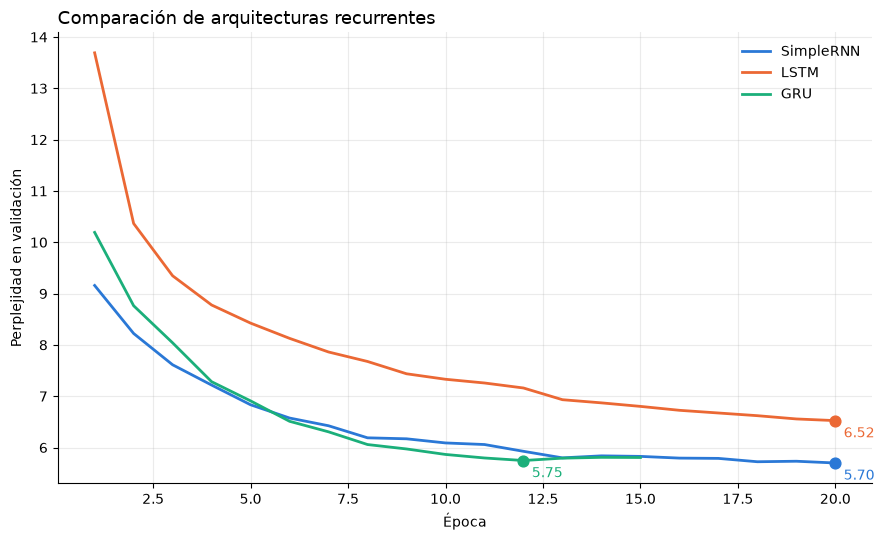

In [117]:
COLORES = {"SimpleRNN": "#2a78d6", "LSTM": "#eb6834", "GRU": "#1baf7a"}

fig, ax = plt.subplots(figsize=(9, 5.5))

for tipo, curva in resultados.items():
    epocas = range(1, len(curva) + 1)
    ax.plot(epocas, curva, color=COLORES[tipo], linewidth=2, label=tipo)
    # marcamos el mínimo de cada curva
    i = int(np.argmin(curva))
    ax.scatter([i + 1], [curva[i]], color=COLORES[tipo], s=60, zorder=3)
    ax.annotate(f"{curva[i]:.2f}", (i + 1, curva[i]), color=COLORES[tipo],
                fontsize=10, xytext=(6, -12), textcoords='offset points')

ax.set_xlabel("Época")
ax.set_ylabel("Perplejidad en validación")
ax.set_title("Comparación de arquitecturas recurrentes", loc='left', fontsize=13)
ax.legend(frameon=False)
ax.grid(alpha=0.25)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

### Primera comparación: resultado y limitación

Con un presupuesto de 20 épocas para las tres arquitecturas, el SimpleRNN obtiene la
mejor perplejidad (5.699), seguido por el GRU (5.747) y el LSTM (6.524). Sin embargo,
**esa comparación no es concluyente**: el gráfico muestra que sólo el GRU convergió.

El GRU alcanza su mínimo en la época 12 y a partir de ahí la perplejidad de validación
repunta, lo que dispara el early stopping en la época 15. El SimpleRNN y el LSTM, en
cambio, llegan al límite de 20 épocas todavía en descenso: el LSTM baja de 13.69 a 6.52
de forma monótona, sin un solo repunte, de modo que su valor final no representa su
techo sino el punto donde se interrumpió el entrenamiento.

Un resultado que sí es sólido es el comportamiento del GRU: termina con un loss de
entrenamiento de 1.37 frente al 1.57 del SimpleRNN, con una perplejidad de validación
prácticamente igual. Ajusta mucho más los datos de entrenamiento sin que eso se traduzca
en mejor generalización, lo que indica mayor capacidad y una tendencia al sobreajuste más
temprana. Por eso es el único que activa el early stopping.

**Decisión:** se reentrenan SimpleRNN y LSTM con un presupuesto ampliado (40 y 60 épocas
respectivamente), manteniendo `patience=3` para que cada arquitectura se detenga cuando
deje de mejorar. El GRU no se reentrena porque ya convergió por sí mismo. De este modo
la comparación pasa a ser entre los tres modelos en su mejor punto, y no entre tres
modelos detenidos arbitrariamente en la misma época.

In [119]:
# Reentrenamiento con presupuesto amplio para las arquitecturas que no convergieron.
# El early stopping (patience=3) corta solo cuando cada una deja de mejorar.
PRESUPUESTO = {"SimpleRNN": 40, "LSTM": 60}

for tipo, n_epocas in PRESUPUESTO.items():
    print(f"\n{'='*50}\nReentrenando {tipo} hasta convergencia\n{'='*50}")

    history_ppl = []
    modelo = construir(tipo)
    modelo.fit(X, y,
               epochs=n_epocas,
               batch_size=256,
               callbacks=[PplCallback(tokenized_sentences_val, history_ppl, patience=3)])

    shutil.copy("my_model.keras", f"modelo_{tipo}.keras")
    resultados[tipo] = list(history_ppl)   # pisa el resultado anterior, el GRU queda intacto

    print(f"{tipo}: mejor perplejidad {min(history_ppl):.3f} en época {np.argmin(history_ppl)+1}")


Reentrenando SimpleRNN hasta convergencia
Epoch 1/40


/Users/bamazon/Documents/pln_1/.venv/lib/python3.11/site-packages/keras/src/layers/core/wrapper.py:25: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


216/217 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - loss: 2.5245
 mean perplexity: 9.197540093243607 

Saved new model!
217/217 ━━━━━━━━━━━━━━━━━━━━ 21s 87ms/step - loss: 2.5243
Epoch 2/40
216/217 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step - loss: 2.1269
 mean perplexity: 8.263902284265534 

Saved new model!
217/217 ━━━━━━━━━━━━━━━━━━━━ 18s 82ms/step - loss: 2.1268
Epoch 3/40
216/217 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step - loss: 2.0338
 mean perplexity: 7.7462022711591025 

Saved new model!
217/217 ━━━━━━━━━━━━━━━━━━━━ 18s 82ms/step - loss: 2.0337
Epoch 4/40
216/217 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step - loss: 1.9548
 mean perplexity: 7.25984909088631 

Saved new model!
217/217 ━━━━━━━━━━━━━━━━━━━━ 19s 87ms/step - loss: 1.9548
Epoch 5/40
216/217 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step - loss: 1.8848
 mean perplexity: 6.899974807491147 

Saved new model!
217/217 ━━━━━━━━━━━━━━━━━━━━ 19s 87ms/step - loss: 1.8848
Epoch 6/40
216/217 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step - loss: 1.8282
 mean perplexity: 6.54501350333051 

S

### Comparación final

Con cada arquitectura entrenada hasta converger (las tres cortan por early stopping),
los resultados son:

| Arquitectura | Mejor perplejidad | Época del mínimo | Épocas corridas | s/época | Tiempo total |
|---|---|---|---|---|---|
| SimpleRNN | 5.701 | 27 | 30 | 19 | ~9 min |
| GRU | 5.747 | 12 | 15 | 57 | ~14 min |
| LSTM | 5.934 | 41 | 44 | 45 | ~33 min |

**Las tres arquitecturas terminan en el mismo rango** (5.70 a 5.93, una diferencia del
4%), y la más simple obtiene el mejor valor. El resultado es contraintuitivo sólo en
apariencia: LSTM y GRU incorporan compuertas para retener información a lo largo de
muchos pasos, y en un modelo de lenguaje por caracteres esa capacidad casi no se usa.
Predecir el carácter siguiente depende sobre todo de los últimos caracteres —la palabra
que se está escribiendo—, de modo que la limitación del SimpleRNN para capturar
dependencias largas no lo penaliza en esta tarea.

A eso se suma el tamaño del corpus: con ~110.000 caracteres de entrenamiento, las
arquitecturas con más parámetros no tienen datos suficientes para aprovechar su
capacidad adicional. El factor limitante es la cantidad de datos, no la arquitectura.

**Velocidad de convergencia.** Medida en épocas, el orden se invierte: el GRU alcanza su
mínimo en la época 12, el SimpleRNN en la 27 y el LSTM en la 41. El GRU extrae más
información por pasada, pero cada pasada le cuesta tres veces más tiempo, así que en
tiempo total el SimpleRNN sigue siendo el más conveniente.

**Sobreajuste.** El GRU es el que más lo evidencia: llega a un loss de entrenamiento de
1.37 frente al 1.55 del SimpleRNN con una perplejidad de validación similar, y es el que
antes empieza a empeorar en validación. Mayor capacidad se traduce acá en ajustar mejor
el texto de entrenamiento, no en generalizar mejor.

**Modelo seleccionado:** SimpleRNN, por mejor perplejidad y menor costo de entrenamiento.
La diferencia con el GRU (0.046) es pequeña, por lo que la elección se apoya también en
el tiempo de cómputo.

## 4. Generación de secuencias

Se generan secuencias con el modelo seleccionado usando tres estrategias:

- **Greedy search:** en cada paso toma el carácter más probable. Es determinista y
  tiende a caer en bucles repetitivos, porque nunca explora alternativas.
- **Beam search determinista:** mantiene las `num_beams` secuencias más probables en
  paralelo y en cada paso expande todas, conservando las mejores. Evalúa la probabilidad
  de la secuencia completa en lugar de la de cada carácter aislado, de modo que puede
  elegir un carácter poco probable si conduce a una continuación mejor.
- **Beam search estocástico:** en lugar de quedarse con los mejores candidatos, los
  muestrea según sus probabilidades. La temperatura escala esas probabilidades antes del
  muestreo: valores bajos exageran las diferencias y concentran la elección en los
  candidatos más probables; valores altos las aplanan y aumentan la aleatoriedad.

In [120]:
from tensorflow import keras

# Cargamos el modelo seleccionado en la comparación
modelo_final = keras.models.load_model("modelo_SimpleRNN.keras")

# La semilla sólo puede contener caracteres presentes en el vocabulario
semilla = "gregorio samsa "
faltantes = set(semilla) - set(char2idx)
print("Caracteres fuera de vocabulario:", faltantes if faltantes else "ninguno")

Caracteres fuera de vocabulario: ninguno


In [121]:
# --- Greedy search ---
print(generate_seq(modelo_final, semilla, max_length=max_context_size, n_words=200))

gregorio samsa de la cabeza de la cabeza de la cabeza de la cabeza de la cabeza de la cabeza de la cabeza de la cabeza de la cabeza de la cabeza de la cabeza de la cabeza de la cabeza de la cabeza de la cabeza de la


In [122]:
# --- Beam search determinista ---
salidas = beam_search(modelo_final, num_beams=5, num_words=100, input=semilla, mode='det')

for i, s in enumerate(salidas):
    print(f"[beam {i}] {decode(s)}\n")

[beam 0] gregorio samsa en la cabeza con la madre y la madre y la habitación de gregorio estaba en la habitación de gregorio

[beam 1] gregorio samsa en la cabeza con la madre y la madre y la habitación de gregorio estaba en la habitación de la cabez

[beam 2] gregorio samsa en la cabeza con la madre y la madre y la habitación de gregorio estaba en la habitación de la madre

[beam 3] gregorio samsa en la cabeza con la madre y la madre y la habitación de gregorio estaba en la habitación de su cuert

[beam 4] gregorio samsa en la cabeza con la madre y la madre y la habitación de gregorio estaba en la habitación de su cuerp



In [123]:
# --- Beam search estocástico: barrido de temperatura ---
for temp in [0.2, 0.5, 1.0, 1.5, 2.0]:
    salidas = beam_search(modelo_final, num_beams=5, num_words=100,
                          input=semilla, temp=temp, mode='sto')
    print(f"{'='*60}\nTemperatura {temp}\n{'='*60}")
    print(decode(salidas[0]), "\n")

Temperatura 0.2
gregorio samsa de la cabeza, no se había sido en la cabeza de la cabeza de la cabeza de la cabeza de la cabeza de s 

Temperatura 0.5
gregorio samsa de la cabeza de la habitación de gregorio había sido en la cabeza de la cabeza de la cabeza de la ca 

Temperatura 1.0
gregorio samsa de la habitación de gregorio estaba en la cabeza de su cuerto de la cabeza en la cabeza, se había so 

Temperatura 1.5
gregorio samsa no si la cabeza dormilizado, pero no se había otra los 
pronto sobre el cambio al padre se apreturab 

Temperatura 2.0
gregorio samsa que podía que había maces por 
la madre el apoderado, todo la mayorar a totivo que ese cerradaba hac 



### Comparación de las tres estrategias

Las tres estrategias se ejecutaron sobre la misma semilla ("gregorio samsa ").

**Greedy search.** Cae de inmediato en un ciclo cerrado: repite "de la cabeza" durante
los 200 caracteres generados, sin variación alguna. Al tomar siempre el carácter más
probable, el modelo llega a un estado desde el cual la continuación más probable lo
devuelve al mismo estado, y queda atrapado.

**Beam search determinista.** Produce tramos sintácticamente correctos y más largos
("en la cabeza con la madre y la madre y la habitación de gregorio estaba en la
habitación de..."), pero también repite, con un ciclo más amplio. Esto muestra que la
repetición no es un defecto exclusivo del greedy sino del criterio determinista en sí:
maximizar la probabilidad de la secuencia favorece las construcciones más frecuentes del
corpus, y las más frecuentes son justamente las que se repiten.

Un segundo efecto, visible al imprimir los cinco beams: **las cinco secuencias son casi
idénticas** y difieren sólo en los últimos caracteres (`la cabeza` / `la madre` /
`su cuerpo`). Los beams no exploran hipótesis distintas sino variantes de una misma, de
modo que aumentar `num_beams` no aporta diversidad; sólo multiplica el costo de cómputo.

**Beam search estocástico.** Es la única estrategia que rompe la repetición, porque
introduce aleatoriedad en la selección en lugar de quedarse siempre con lo más probable.
El precio es la corrección: a medida que sube la temperatura aparecen palabras
inexistentes y la sintaxis se degrada.

| Estrategia | Repetición | Diversidad | Corrección |
|---|---|---|---|
| Greedy | Ciclo cerrado inmediato | Nula | Alta (texto correcto pero vacío) |
| Beam determinista | Ciclo más amplio | Muy baja entre beams | Alta |
| Beam estocástico (temp 1.5) | No se repite | Alta | Media |

En conjunto, el experimento muestra que la calidad del texto generado depende tanto de la
estrategia de decodificación como del modelo: con el mismo modelo entrenado se obtiene
desde una repetición estéril hasta texto variado, según cómo se recorra la distribución
de probabilidades que el modelo entrega.

## Conclusiones

**Sobre las arquitecturas.** Entrenadas hasta converger, las tres terminan en el mismo
rango de perplejidad (SimpleRNN 5.701, GRU 5.747, LSTM 5.934) y la más simple obtiene el
mejor valor con un tercio del tiempo de cómputo. Las compuertas de LSTM y GRU existen
para retener información a lo largo de muchos pasos, y un modelo de lenguaje por
caracteres apenas usa esa capacidad: el carácter siguiente depende sobre todo de los
últimos caracteres escritos. Sumado al tamaño del corpus (~110.000 caracteres de
entrenamiento), la capacidad adicional no encuentra datos para aprovecharse. El factor
limitante acá son los datos, no la arquitectura.

**Sobre la velocidad de convergencia.** Medido en épocas el orden se invierte —GRU
converge en 12, SimpleRNN en 27, LSTM en 41—, pero cada época del GRU cuesta tres veces
más. Comparar modelos con un presupuesto fijo de épocas, como se hizo en la primera
corrida, mide velocidad de convergencia y no calidad final: fue necesario dejar que cada
arquitectura se detuviera por sí misma para que la comparación tuviera sentido.

**Sobre lo que aprendió el modelo.** Pese a trabajar carácter por carácter y sin ninguna
noción de qué es una palabra, el modelo genera texto pronunciable, mayormente formado por
palabras reales del español y con acentuación correcta. El vocabulario que produce es el
del corpus (`gregorio`, `la madre`, `el padre`, `el apoderado`, `la habitación`), de modo
que capturó tanto la ortografía del idioma como el contenido del texto de entrenamiento.

**Sobre las estrategias de generación.** Con un mismo modelo entrenado, la estrategia de
decodificación cambia por completo el resultado. Las estrategias deterministas —greedy y
beam search— caen en repetición, porque maximizar la probabilidad favorece las
construcciones más frecuentes del corpus; el beam search además produce hipótesis casi
idénticas entre sí, de modo que ampliar el número de beams agrega costo sin agregar
diversidad. Sólo el muestreo estocástico rompe la repetición, y la temperatura regula el
compromiso entre diversidad y corrección: alrededor de 1.5 se obtiene el mejor equilibrio
para este modelo.

**Limitaciones y mejoras posibles.** El corpus es el principal cuello de botella: con un
texto más extenso las arquitecturas con compuertas probablemente sí mostrarían ventaja.
Otras líneas de mejora serían reservar un índice para el padding —actualmente el relleno
comparte índice con un carácter real del vocabulario, de modo que el modelo no puede
distinguirlos—, entrenar una capa de embedding de caracteres en lugar de la codificación
one-hot, y aplicar la temperatura sobre los logits de cada paso en vez de sobre las
probabilidades acumuladas de las secuencias, lo que daría un control más directo sobre la
aleatoriedad de la generación.